# Opción 2 — LT por camino geodésico mínimo centrado

1. **Extremos A y B** por diámetro geodésico dentro de la máscara (`skimage.graph.MCP_Geometric`, costo 1 dentro / `inf` fuera): A = punto geodésicamente más lejano de un punto cualquiera; B = más lejano desde A.
2. **Camino A→B** con `route_through_array` y costo `1/(dt+1)**p` (`dt` = transformada de distancia) → el camino se mantiene en el eje del cuerpo.
3. **Suavizado** (Savitzky–Golay o spline) para quitar el escalonado de píxeles.
4. Se reportan `LT_curva_cm` (largo del camino suavizado) y `LT_recta_cm` (distancia euclídea A–B).

Las longitudes se miden en cm proyectando los puntos con la **homografía** de las 4 esquinas del ArUco (corrige la perspectiva de la cámara); el factor único `px_por_cm` se conserva en las columnas `*_escalar_cm` para comparar. La escala `px_por_cm` sale del ArUco (ID 17, 5 cm). Si el pez es muy grande se reescala la máscara (y `px_por_cm` en la misma proporción) para acelerar.

**Opción 2b — eje + extensión recta.** El camino geodésico termina a veces en un "gancho" hacia la punta de un lóbulo caudal. La 2b usa el camino solo en el cuerpo (hasta el 70 % de su longitud) y cierra la cola con un tramo recto en la dirección del eje hasta la proyección del píxel más lejano de la máscara (`LT_axial_cm`). `LT_curva_cm` y `LT_recta_cm` se conservan para comparar.

In [1]:
%pip install -q numpy scipy opencv-contrib-python scikit-image matplotlib pandas ultralytics

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from scipy.signal import savgol_filter
from scipy.interpolate import splprep, splev
from skimage.graph import MCP_Geometric, route_through_array

import fish_length_utils as U

# ---------------- parámetros ----------------
N_IMAGENES = None            # None = todas las imágenes de examples/; o un entero (primeras N)
CARPETA_IMAGENES = U.EXAMPLES_DIR
WEIGHTS = U.WEIGHTS
CONF, IMGSZ = U.CONF, U.IMGSZ
ARUCO_ID, TAMANO_ARUCO_CM = U.ARUCO_ID, U.TAMANO_ARUCO_CM
P_COSTO = 2                  # exponente p del costo 1/(dt+1)**p (probar 1, 2 y 3)
P_COMPARAR = (1, 2, 3)       # valores de p que se comparan en el CSV (el principal es P_COSTO)
SUAVIZADO = "savgol"         # "savgol" o "spline"
SUAV_FRAC = 0.15             # savgol: ventana = SUAV_FRAC * n_puntos del camino (impar, >= 11)
SPLINE_S_PX = 2.0            # spline: s = SPLINE_S_PX**2 * n_puntos (desvío cuadrático medio permitido, px)
LADO_MAX_PX = 1200           # reescala la máscara recortada si su lado mayor lo supera; None = sin reescalar
# ---- opción 2b (eje + extensión recta): fracciones de la longitud del camino
F_INI, F_REF, F_FIN = 0.55, 0.70, 0.80   # dirección del eje = punto(F_FIN) - punto(F_INI); origen O = punto(F_REF)
F_REF_DOBLADA = 0.60                     # F_REF alternativo si la cola está doblada
ANGULO_COLA_MAX = 30                     # grados entre el eje y el tramo 80 %-100 % para marcar cola_doblada
USAR_HOMOGRAFIA = True       # True: longitudes en cm con la homografía del ArUco (corrige perspectiva); False: factor px_por_cm
SALIDA_IMGS = Path("outputs/opcion2")
SALIDA_CSV = Path("outputs/resultados_opcion2.csv")

## Funciones

In [3]:
def preparar_mascara(mask, px_por_cm, lado_max=LADO_MAX_PX):
    """Limpia la máscara, la recorta a su bounding box (con margen de 2 px) y, si el lado mayor supera `lado_max`,
    la reescala. Devuelve (m_bool, px_por_cm_esc, escala, (x0, y0)). Las coordenadas del recorte reescalado se llevan
    a la imagen original con: p_orig = p / escala + (x0, y0).  px_por_cm_esc = px_por_cm * escala."""
    m = U.limpiar_mascara(mask)
    ys, xs = np.nonzero(m)
    x0, y0 = max(xs.min() - 2, 0), max(ys.min() - 2, 0)
    m = m[y0:ys.max() + 3, x0:xs.max() + 3]
    escala = 1.0
    if lado_max and max(m.shape) > lado_max:
        escala = lado_max / max(m.shape)
        m = cv2.resize(m, None, fx=escala, fy=escala, interpolation=cv2.INTER_NEAREST)
    return m > 0, px_por_cm * escala, escala, (x0, y0)


def mas_lejano_geodesico(mask_bool, origen):
    """Punto (fila, col) de la máscara geodésicamente más lejano de `origen` (costo 1 dentro, inf fuera)."""
    costo = np.where(mask_bool, 1.0, np.inf)
    acum, _ = MCP_Geometric(costo, fully_connected=True).find_costs([tuple(origen)])
    acum = np.where(np.isfinite(acum), acum, -1)
    return np.unravel_index(np.argmax(acum), acum.shape)


def extremos_geodesicos(mask_bool):
    """Extremos A y B por diámetro geodésico (doble barrido). Devuelve (A, B) como (fila, col)."""
    ys, xs = np.nonzero(mask_bool)
    k = len(ys) // 2                      # un píxel cualquiera de la máscara
    A = mas_lejano_geodesico(mask_bool, (ys[k], xs[k]))
    B = mas_lejano_geodesico(mask_bool, A)
    return tuple(int(v) for v in A), tuple(int(v) for v in B)


def camino_centrado(mask_bool, A, B, p=P_COSTO):
    """Camino mínimo A→B con costo 1/(dt+1)**p dentro de la máscara (inf fuera). Devuelve array (N, 2) en (x, y)."""
    dt = distance_transform_edt(mask_bool)
    costo = np.where(mask_bool, 1.0 / (dt + 1.0) ** p, np.inf)
    ruta, _ = route_through_array(costo, A, B, fully_connected=True, geometric=True)
    ruta = np.asarray(ruta, dtype=np.float64)
    return ruta[:, ::-1]                  # (fila, col) -> (x, y)


def suavizar_camino(xy, metodo=SUAVIZADO, frac=SUAV_FRAC, s_px=SPLINE_S_PX):
    """Suaviza el camino (N, 2) manteniendo los extremos fijos. 'savgol' (ventana relativa, polinomio de grado 3)
    o 'spline' (spline cúbica suavizada)."""
    n = len(xy)
    if n < 15:
        return xy
    if metodo == "savgol":
        w = max(11, int(frac * n) | 1)
        w = min(w, n if n % 2 else n - 1)
        sm = np.column_stack([savgol_filter(xy[:, 0], w, 3, mode="interp"), savgol_filter(xy[:, 1], w, 3, mode="interp")])
    else:
        tck, _ = splprep(xy.T, s=(s_px ** 2) * n, k=3)
        sm = np.column_stack(splev(np.linspace(0, 1, n * 2), tck))
    sm[0], sm[-1] = xy[0], xy[-1]         # los extremos geodésicos se respetan
    return sm


def longitud(xy):
    """Longitud de la poligonal (N, 2)."""
    return float(np.sum(np.linalg.norm(np.diff(xy, axis=0), axis=1)))


def _axial(mb, path, cum, dt_unused, f_ini, f_ref, f_fin):
    """Cálculo de la opción 2b para un camino ya orientado cabeza→cola (filas/cols) y su longitud acumulada `cum`.
    Devuelve dict con L_px, path_final, punta_lobulo, d, O, t_max, angulo_cola (grados) o None si el eje es degenerado."""
    idx = lambda f: min(int(np.searchsorted(cum, f * cum[-1])), len(path) - 1)
    i0, i1, i2 = idx(f_ini), idx(f_ref), idx(f_fin)
    d = path[i2] - path[i0]
    nd = np.linalg.norm(d)
    if nd < 1e-9:
        return None
    d = d / nd
    O = path[i1]
    coords = np.argwhere(mb)
    t = (coords - O) @ d
    t_max = float(t.max())
    punta_lobulo = coords[int(t.argmax())]
    punta_eje = O + t_max * d
    cola = path[-1] - path[i2]                      # tramo 80 %-100 % del camino (donde aparece el gancho)
    ncola = np.linalg.norm(cola)
    ang = float(np.degrees(np.arccos(np.clip(d @ cola / ncola, -1, 1)))) if ncola > 1e-9 else 0.0
    return dict(L_px=float(cum[i1] + t_max), path_final=np.vstack([path[:i1 + 1], punta_eje]),
                punta_lobulo=punta_lobulo, t_max=t_max, angulo_cola=ang, f_ref=f_ref)


def lt_axial(mb, path_xy, px_por_cm, f_ini=F_INI, f_ref=F_REF, f_fin=F_FIN):
    """Opción 2b: LT = arco del eje en el cuerpo + tramo recto hasta la punta del lóbulo más largo.

    `mb`: máscara booleana (recorte, escala de trabajo); `path_xy`: camino suavizado (N, 2) en (x, y).
    1) Orienta cabeza→cola (la cola es el extremo con menor DT media en el 20 % inicial/final).
    2) Eje = dirección entre los puntos al `f_ini` y `f_fin` de la longitud; origen O al `f_ref`.
    3) Proyecta todos los píxeles de la máscara sobre el eje: el de mayor t es la punta del lóbulo más largo.
    Si el ángulo entre el eje y el tramo 80 %-100 % supera ANGULO_COLA_MAX se marca `cola_doblada` y se repite con
    F_REF_DOBLADA. Devuelve dict con LT_axial_cm, path_final / hocico / punta_lobulo / punta_eje en (x, y) de la
    máscara de trabajo, cola_doblada, angulo_cola, f_ref_usado, tramo_recto_px. Con datos insuficientes: LT_axial_cm=NaN."""
    nan = dict(LT_axial_cm=np.nan, path_final=None, hocico=None, punta_lobulo=None, cola_doblada=False,
               angulo_cola=np.nan, f_ref_usado=np.nan, tramo_recto_px=np.nan)
    if len(path_xy) < 15 or mb.sum() < 50:
        return nan
    path = np.asarray(path_xy, float)[:, ::-1]                      # (x, y) -> (fila, col)
    dt = distance_transform_edt(mb)
    dt_medio = lambda s: dt[s.round().astype(int)[:, 0], s.round().astype(int)[:, 1]].mean()
    k = max(3, int(0.2 * len(path)))
    if dt_medio(path[:k]) < dt_medio(path[-k:]):                    # la cabeza debe ser el extremo "grueso"
        path = path[::-1]
    cum = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    if cum[-1] < 1e-9:
        return nan
    r = _axial(mb, path, cum, dt, f_ini, f_ref, f_fin)
    if r is None:
        return nan
    doblada = r["angulo_cola"] > ANGULO_COLA_MAX
    if doblada:
        r2 = _axial(mb, path, cum, dt, f_ini, F_REF_DOBLADA, f_fin)
        r = r2 or r
    pf = r["path_final"]
    xy = lambda q: np.asarray(q, float)[::-1]
    return dict(LT_axial_cm=r["L_px"] / px_por_cm, path_final=pf[:, ::-1], hocico=xy(path[0]),
                punta_lobulo=xy(r["punta_lobulo"]), cola_doblada=bool(doblada), angulo_cola=r["angulo_cola"],
                f_ref_usado=r["f_ref"], tramo_recto_px=float(r["t_max"]))


def medir_geodesica(mask, px_por_cm, p=P_COSTO, metodo=SUAVIZADO, axial=True, H=None):
    """LT por camino geodésico centrado. Devuelve dict con LT_curva_cm, LT_recta_cm (y LT_axial_cm), camino (px de la
    imagen original), extremos A y B (x, y), contorno, escala usada y tiempo de cómputo (s).

    Los extremos y el camino se buscan en píxeles. Si se pasa la homografía `H` (px -> cm), las longitudes se calculan
    proyectando los puntos a cm (corrige perspectiva); si H es None se usa el factor `px_por_cm`. Las versiones con
    factor único siempre se devuelven en las claves *_escalar_cm."""
    t = U.cronometro()
    mb, ppc, escala, (x0, y0) = preparar_mascara(mask, px_por_cm)
    A, B = extremos_geodesicos(mb)
    ruta = camino_centrado(mb, A, B, p)
    liso = suavizar_camino(ruta, metodo)
    a_xy, b_xy = np.array(A[::-1], float), np.array(B[::-1], float)
    a_orig = lambda q: np.asarray(q) / escala + (x0, y0)
    camino, a, b = a_orig(liso), a_orig(a_xy), a_orig(b_xy)
    L = (lambda pts: U.longitud_cm(pts, H)) if H is not None else (lambda pts: longitud(pts) / px_por_cm)
    r = dict(LT_curva_cm=L(camino), LT_recta_cm=L(np.vstack([a, b])), LT_curva_sin_suavizar_cm=L(a_orig(ruta)),
             LT_curva_escalar_cm=longitud(liso) / ppc, LT_recta_escalar_cm=float(np.linalg.norm(a_xy - b_xy)) / ppc,
             camino=camino, a=a, b=b, contour=U.mayor_contorno(U.limpiar_mascara(mask)), escala=escala)
    ax = lt_axial(mb, liso, ppc) if axial else None
    if ax is not None:
        r.update(LT_axial_escalar_cm=ax["LT_axial_cm"], LT_axial_cm=ax["LT_axial_cm"], cola_doblada=ax["cola_doblada"],
                 angulo_cola=ax["angulo_cola"], f_ref_usado=ax["f_ref_usado"], tramo_recto_cm=ax["tramo_recto_px"] / ppc)
        if ax["path_final"] is not None:
            r.update(camino_axial=a_orig(ax["path_final"]), hocico=a_orig(ax["hocico"]), punta_lobulo=a_orig(ax["punta_lobulo"]))
            r["LT_axial_cm"] = L(r["camino_axial"])
            r["tramo_recto_cm"] = L(r["camino_axial"][-2:])      # último tramo (recto) en cm
    r["tiempo_s"] = t()
    return r

## Procesamiento de todas las imágenes

In [4]:
model = U.cargar_modelo(WEIGHTS)
filas, anotadas = [], {}

for path in U.listar_imagenes(CARPETA_IMAGENES, N_IMAGENES):
    prep = U.preparar_imagen(path, model, CONF, IMGSZ, ARUCO_ID, TAMANO_ARUCO_CM)
    base = dict(imagen=path.name, px_por_cm=prep["px_por_cm"], estado=prep["estado"], p_costo=P_COSTO,
                suavizado=SUAVIZADO, suav_frac=SUAV_FRAC, spline_s_px=SPLINE_S_PX, lado_max_px=LADO_MAX_PX,
                usar_homografia=USAR_HOMOGRAFIA, f_ini=F_INI, f_ref=F_REF, f_fin=F_FIN, conf=CONF, imgsz=IMGSZ, aruco_id=ARUCO_ID,
                tamano_aruco_cm=TAMANO_ARUCO_CM)
    if prep["estado"] != "ok":
        print(f"{path.name}: saltada ({prep['estado']})")
        filas.append(dict(base, pez=None))
        continue

    peces = []
    for k, (m, score) in enumerate(zip(prep["masks"], prep["confs"])):
        H = prep["H"] if USAR_HOMOGRAFIA else None
        r = medir_geodesica(m, prep["px_por_cm"], P_COSTO, H=H)
        fila = dict(base, pez=k, score=round(score, 4), escala_mascara=round(r["escala"], 4),
                    LT_curva_cm=round(r["LT_curva_cm"], 3), LT_recta_cm=round(r["LT_recta_cm"], 3),
                    LT_axial_cm=round(r.get("LT_axial_cm", np.nan), 3),
                    LT_curva_escalar_cm=round(r["LT_curva_escalar_cm"], 3), LT_recta_escalar_cm=round(r["LT_recta_escalar_cm"], 3),
                    LT_axial_escalar_cm=round(r.get("LT_axial_escalar_cm", np.nan), 3), cola_doblada=r.get("cola_doblada"),
                    angulo_cola_grados=round(r.get("angulo_cola", np.nan), 1), f_ref_usado=r.get("f_ref_usado"),
                    tramo_recto_cm=round(r.get("tramo_recto_cm", np.nan), 3),
                    LT_curva_sin_suavizar_cm=round(r["LT_curva_sin_suavizar_cm"], 3), tiempo_s=round(r["tiempo_s"], 4))
        for pp in P_COMPARAR:             # comparación de exponentes p
            if pp != P_COSTO:
                fila[f"LT_curva_cm_p{pp}"] = round(medir_geodesica(m, prep["px_por_cm"], pp, axial=False, H=H)["LT_curva_cm"], 3)
            else:
                fila[f"LT_curva_cm_p{pp}"] = fila["LT_curva_cm"]
        filas.append(fila)
        if "camino_axial" in r:           # método axial (2b): camino en rojo, hocico y punta del lóbulo en amarillo
            peces.append(dict(contour=r["contour"],
                              capas=[dict(tipo="linea", pts=r["camino_axial"], color=U.COLOR_CAMINO),
                                     dict(tipo="puntos", pts=[r["hocico"], r["punta_lobulo"]], color=U.COLOR_EXTREMOS)],
                              texto=f"LT axial {r['LT_axial_cm']:.1f} cm | recta {r['LT_recta_cm']:.1f} cm",
                              label_xy=r["punta_lobulo"]))
        print(f"{path.name} pez {k}: curva {r['LT_curva_cm']:.2f} | recta {r['LT_recta_cm']:.2f} | "
              f"axial {r.get('LT_axial_cm', np.nan):.2f} cm | cola_doblada={r.get('cola_doblada')} | {r['tiempo_s']:.2f} s")

    out = U.dibujar_resultados(prep["img"], peces, [prep["aruco_corners"][prep["aruco_idx"]]], TAMANO_ARUCO_CM)
    U.guardar_rgb(out, SALIDA_IMGS / path.name)
    anotadas[path.name] = out

cero_peces.jpg: saltada (sin_aruco)
example (1).jpg pez 0: curva 32.17 | recta 31.29 | axial 31.35 cm | cola_doblada=False | 0.12 s
example (1).jpg pez 1: curva 27.56 | recta 26.95 | axial 27.59 cm | cola_doblada=False | 0.09 s
example (10).jpg pez 0: curva 17.96 | recta 17.43 | axial 17.69 cm | cola_doblada=False | 1.21 s
example (11).jpg pez 0: curva 27.26 | recta 26.85 | axial 28.04 cm | cola_doblada=False | 0.09 s
example (11).jpg pez 1: curva 20.46 | recta 19.55 | axial 19.53 cm | cola_doblada=True | 0.08 s
example (11).jpg pez 2: curva 21.35 | recta 20.36 | axial 20.08 cm | cola_doblada=True | 0.08 s
example (2).jpg pez 0: curva 32.00 | recta 30.60 | axial 30.61 cm | cola_doblada=True | 0.22 s
example (3).jpg pez 0: curva 29.56 | recta 26.49 | axial 27.75 cm | cola_doblada=True | 0.18 s
example (4).jpg pez 0: curva 16.90 | recta 16.47 | axial 16.53 cm | cola_doblada=False | 0.06 s
example (4).jpg pez 1: curva 19.06 | recta 17.63 | axial 17.89 cm | cola_doblada=True | 0.06 s
examp

In [5]:
df = pd.DataFrame(filas)
SALIDA_CSV.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SALIDA_CSV, index=False)
print(f"CSV guardado en {SALIDA_CSV} ({len(df)} filas)")
df

CSV guardado en outputs\resultados_opcion2.csv (20 filas)


,imagen,px_por_cm,estado,p_costo,suavizado,suav_frac,spline_s_px,lado_max_px,usar_homografia,f_ini,...,LT_axial_escalar_cm,cola_doblada,angulo_cola_grados,f_ref_usado,tramo_recto_cm,LT_curva_sin_suavizar_cm,tiempo_s,LT_curva_cm_p1,LT_curva_cm_p2,LT_curva_cm_p3
0,cero_peces.jpg,NaN,sin_aruco,2,savgol,0.15,2.0,1200,True,0.55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,example (1).jpg,16.303056,ok,2,savgol,0.15,2.0,1200,True,0.55,...,31.508,False,24.1,0.7,8.833,33.074,0.1198,32.152,32.170,32.205
2,example (1).jpg,16.303056,ok,2,savgol,0.15,2.0,1200,True,0.55,...,27.682,False,17.6,0.7,8.270,28.791,0.0942,27.558,27.558,27.566
3,example (10).jpg,97.571352,ok,2,savgol,0.15,2.0,1200,True,0.55,...,19.027,False,17.8,0.7,4.915,18.587,1.2143,17.961,17.963,17.971
4,example (11).jpg,15.152978,ok,2,savgol,0.15,2.0,1200,True,0.55,...,26.908,False,13.2,0.7,8.927,28.117,0.0922,27.227,27.261,27.249
5,example (11).jpg,15.152978,ok,2,savgol,0.15,2.0,1200,True,0.55,...,18.881,True,30.9,0.6,7.313,21.174,0.0750,20.305,20.463,20.496
6,example (11).jpg,15.152978,ok,2,savgol,0.15,2.0,1200,True,0.55,...,19.907,True,40.8,0.6,7.339,21.996,0.0770,21.290,21.353,21.420
7,example (2).jpg,22.040458,ok,2,savgol,0.15,2.0,1200,True,0.55,...,35.082,True,37.8,0.6,10.601,32.925,0.2164,31.917,32.003,32.050
8,example (3).jpg,18.407064,ok,2,savgol,0.15,2.0,1200,True,0.55,...,27.889,True,67.1,0.6,9.965,30.921,0.1810,29.443,29.564,29.636
9,example (4).jpg,14.580849,ok,2,savgol,0.15,2.0,1200,True,0.55,...,15.913,False,25.8,0.7,4.747,18.082,0.0591,16.860,16.899,16.922


## Comparación `LT_curva` vs `LT_axial` (el gancho)

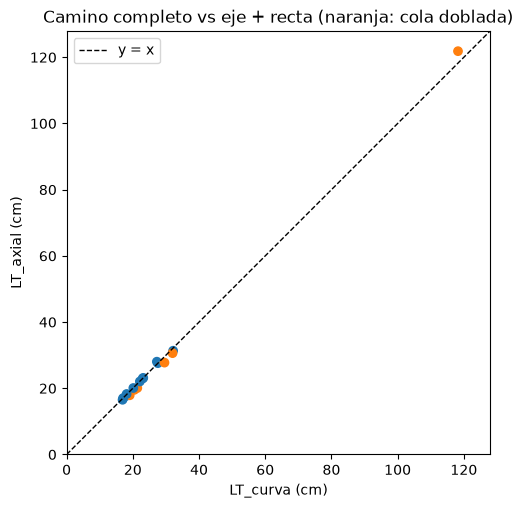

,imagen,pez,LT_curva_cm,LT_recta_cm,LT_axial_cm,dif_curva_axial_cm,dif_curva_axial_pct,cola_doblada
19,mal_angulo.jpg,0.0,118.23,118.19,121.84,-3.61,-2.96,True
8,example (3).jpg,0.0,29.56,26.49,27.75,1.81,6.53,True
7,example (2).jpg,0.0,32.00,30.60,30.61,1.39,4.54,True
6,example (11).jpg,2.0,21.35,20.36,20.08,1.27,6.32,True
10,example (4).jpg,1.0,19.06,17.63,17.89,1.17,6.55,True
5,example (11).jpg,1.0,20.46,19.55,19.53,0.93,4.78,True
1,example (1).jpg,0.0,32.17,31.29,31.35,0.82,2.62,False
4,example (11).jpg,0.0,27.26,26.85,28.04,-0.78,-2.77,False
9,example (4).jpg,0.0,16.90,16.47,16.53,0.37,2.24,False
3,example (10).jpg,0.0,17.96,17.43,17.69,0.27,1.52,False


In [6]:
ok = df.dropna(subset=["LT_axial_cm"]).copy()
ok["dif_curva_axial_cm"] = ok["LT_curva_cm"] - ok["LT_axial_cm"]
ok["dif_curva_axial_pct"] = 100 * ok["dif_curva_axial_cm"] / ok["LT_axial_cm"]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = [0, max(ok["LT_curva_cm"].max(), ok["LT_axial_cm"].max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="y = x")
ax.scatter(ok["LT_curva_cm"], ok["LT_axial_cm"], c=np.where(ok["cola_doblada"].astype(bool), "tab:orange", "tab:blue"))
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("LT_curva (cm)"); ax.set_ylabel("LT_axial (cm)"); ax.set_title("Camino completo vs eje + recta (naranja: cola doblada)")
ax.legend(); plt.show()

cols = ["imagen", "pez", "LT_curva_cm", "LT_recta_cm", "LT_axial_cm", "dif_curva_axial_cm", "dif_curva_axial_pct", "cola_doblada"]
ok.reindex(ok["dif_curva_axial_cm"].abs().sort_values(ascending=False).index)[cols].head(10).round(2)

## Validación contra medición manual (si existe `outputs/referencia_manual.csv`)

Columnas esperadas: `imagen`, `pez` y `LT_manual_cm`.

In [7]:
REF_CSV = Path("outputs/referencia_manual.csv")
if REF_CSV.exists():
    ref = pd.read_csv(REF_CSV)
    v = ok.merge(ref[["imagen", "pez", "LT_manual_cm"]], on=["imagen", "pez"])
    filas_val = []
    for col in ("LT_curva_cm", "LT_recta_cm", "LT_axial_cm"):
        e = v[col] - v["LT_manual_cm"]
        filas_val.append(dict(variante=col, n=len(v), sesgo_cm=e.mean(), MAE_cm=e.abs().mean(), RMSE_cm=np.sqrt((e**2).mean()),
                              MAPE_pct=(100 * e.abs() / v["LT_manual_cm"]).mean()))
    display(pd.DataFrame(filas_val).round(3))
else:
    print(f"No existe {REF_CSV}: se omite la validación.")

No existe outputs\referencia_manual.csv: se omite la validación.


## Mosaico (método axial)

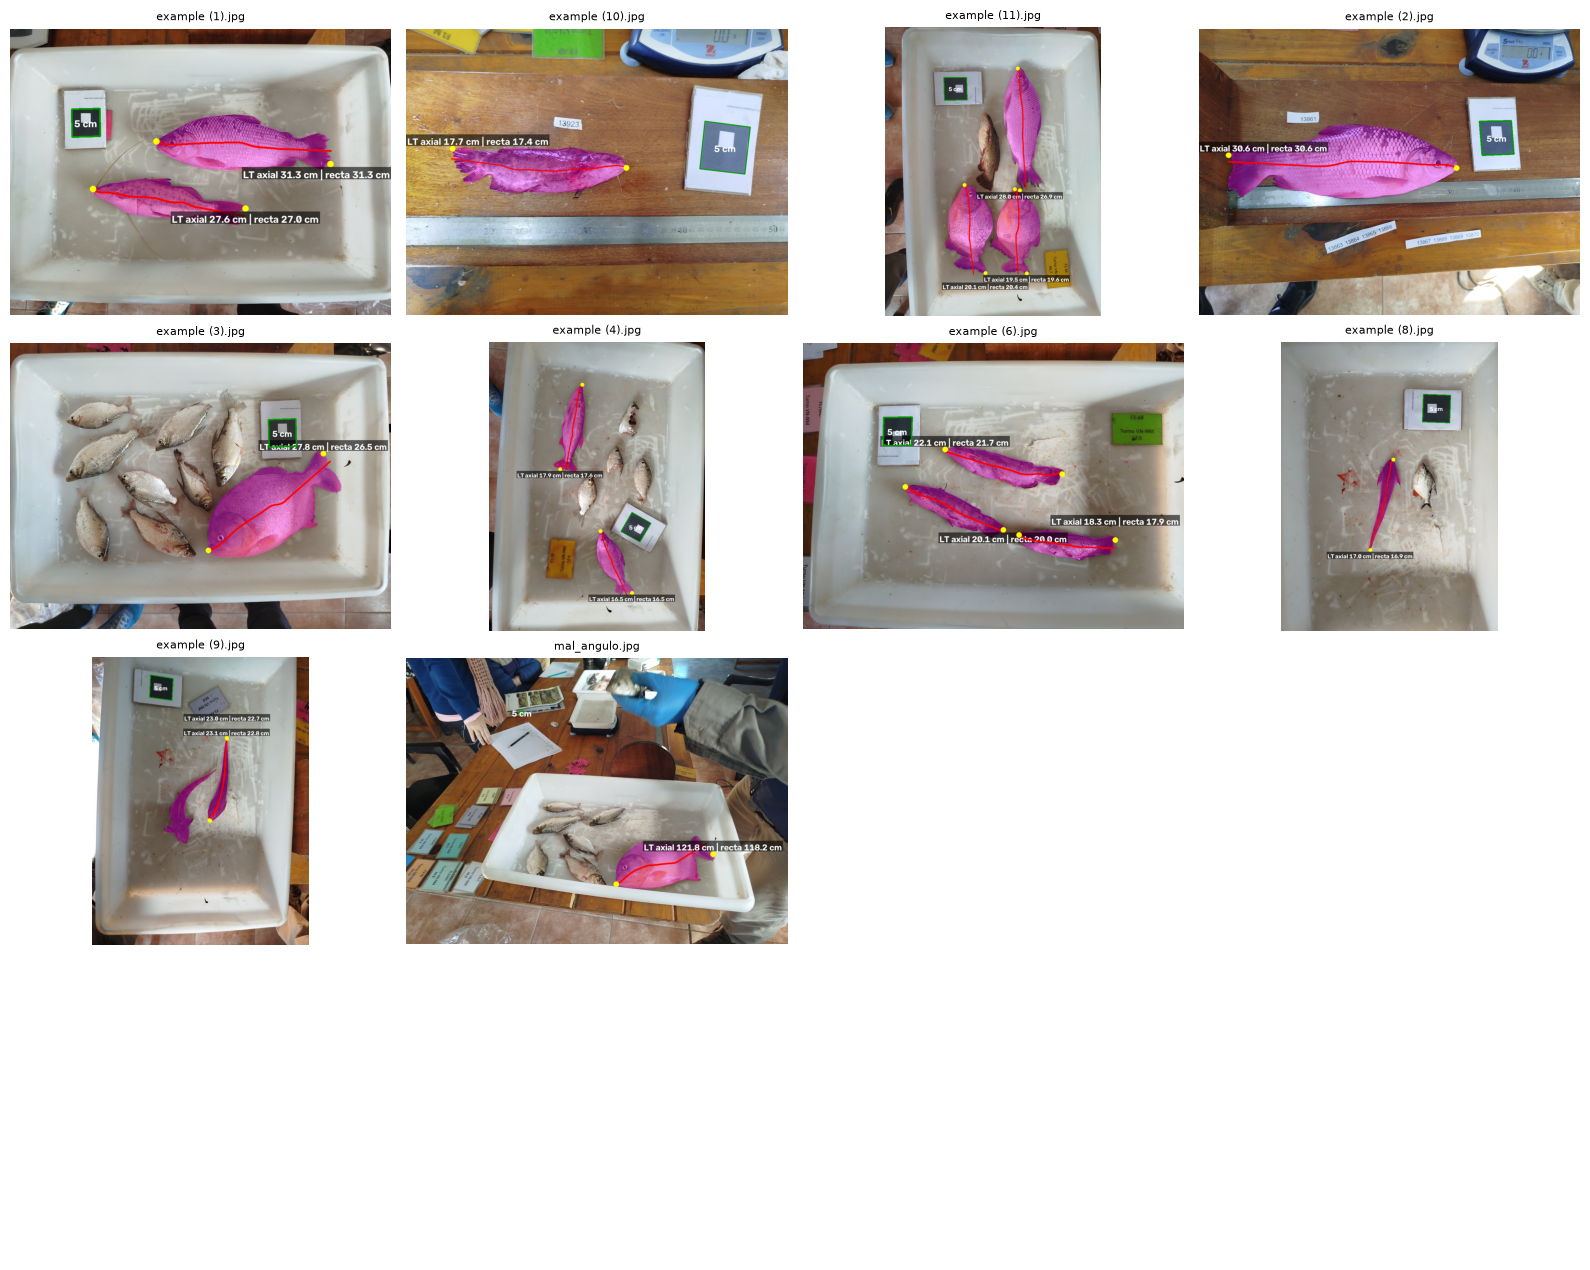

In [8]:
nombres = list(anotadas)
n = 16 if len(nombres) > 9 else 9
lado = 4 if n == 16 else 3
fig, axes = plt.subplots(lado, lado, figsize=(4 * lado, 3.2 * lado))
for a in axes.ravel():
    a.axis("off")
for a, nombre in zip(axes.ravel(), nombres[:n]):
    a.imshow(anotadas[nombre]); a.set_title(nombre, fontsize=8)
plt.tight_layout()
Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/mosaico_opcion2.png", dpi=150)
plt.show()

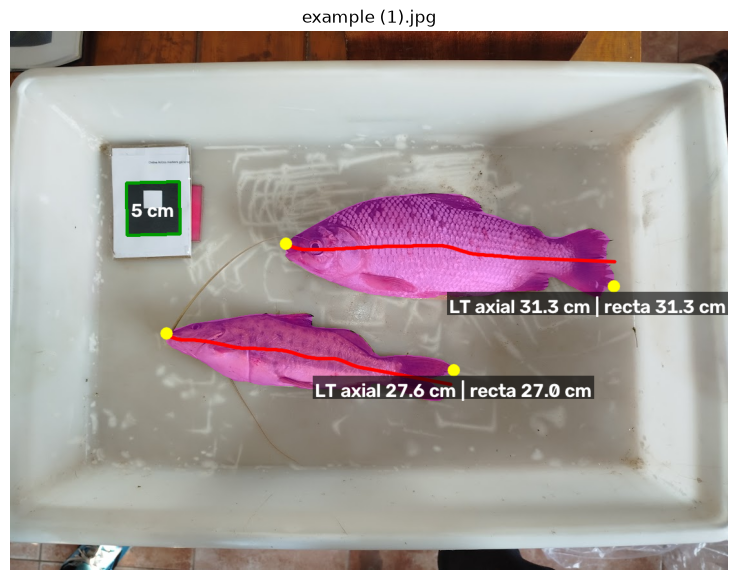

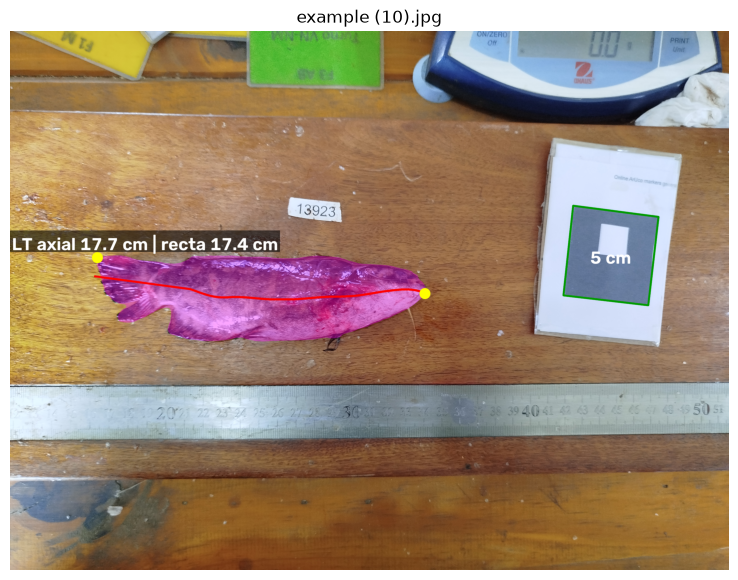

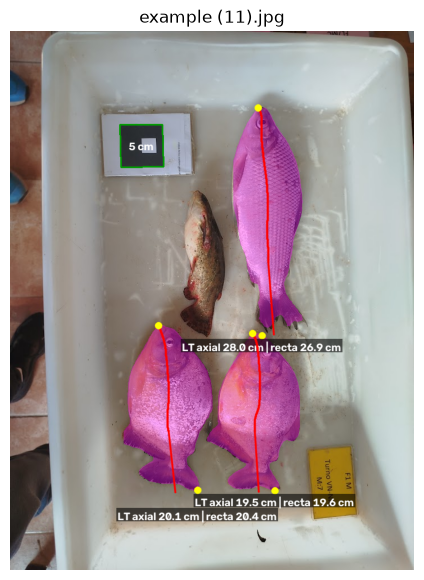

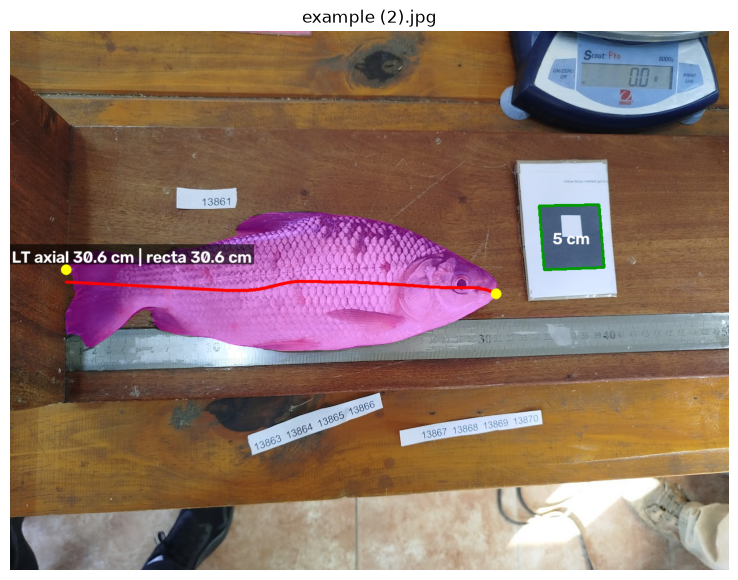

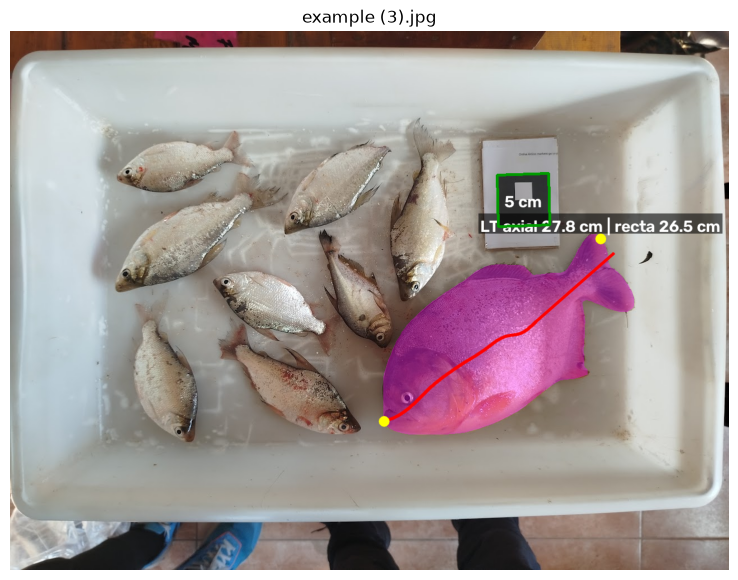

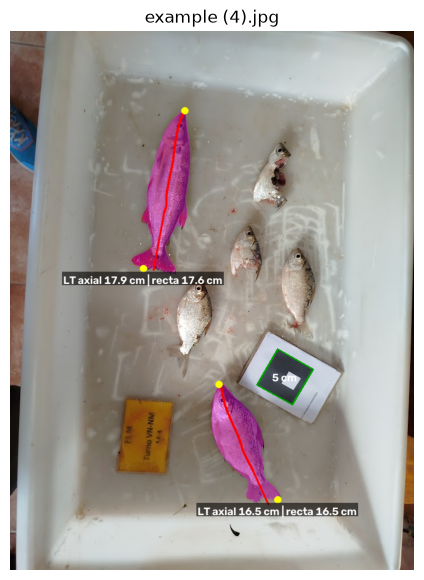

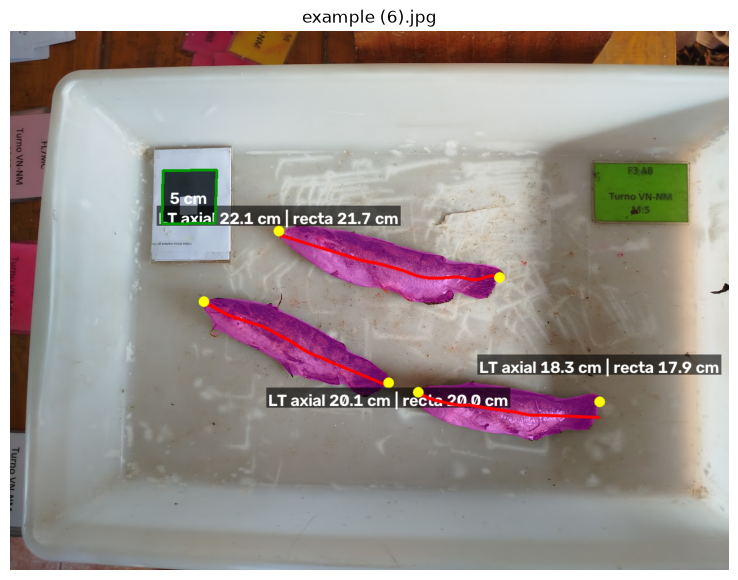

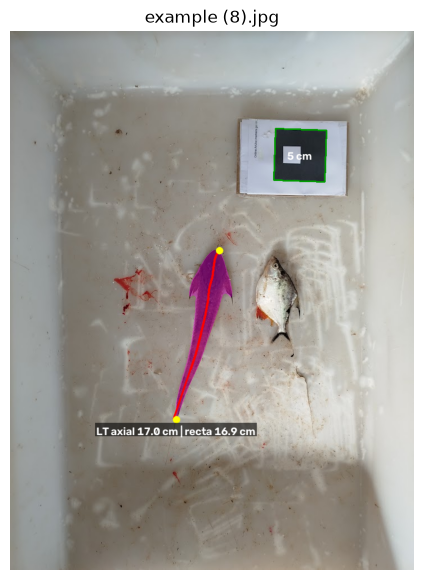

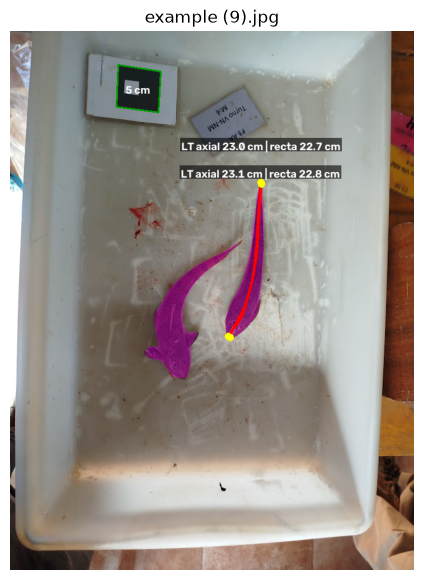

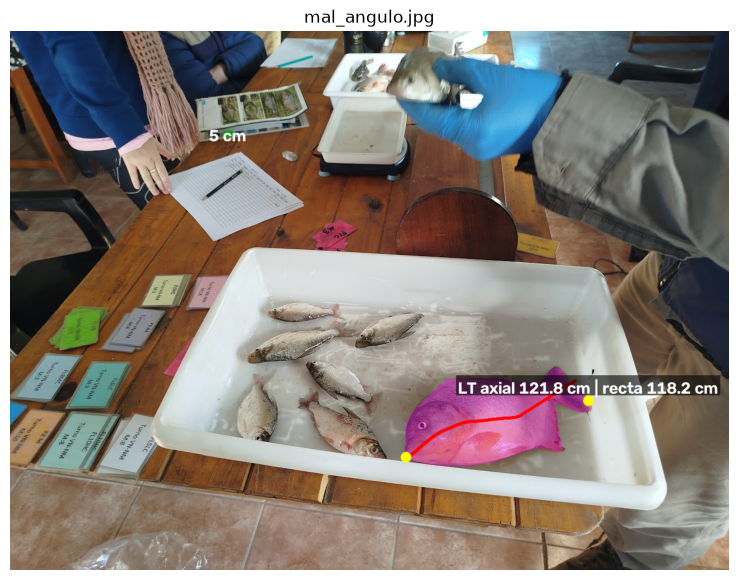

In [9]:
# Vista previa de las primeras imágenes anotadas
for nombre, im in list(anotadas.items())[:]:
    plt.figure(figsize=(10, 7)); plt.imshow(im); plt.title(nombre); plt.axis("off"); plt.show()

## Resumen y limitaciones

**Resultados** (`outputs/resultados_opcion2.csv`, imágenes en `outputs/opcion2/`): mismas 16 detecciones que la opción 1. Cómputo ~0.06–0.2 s por pez (≈1 s con reescalado 0.65 en la imagen de 4000×3000). El CSV incluye `LT_curva_cm` para `p=1,2,3`: las diferencias entre p son pequeñas (≤0.2 cm en la mayoría de los casos) y `p=2` es un buen compromiso. El suavizado reduce ~2–5 % la longitud respecto del camino pixelado (`LT_curva_sin_suavizar_cm`).

**Observaciones**
- `LT_recta_cm` (A–B) coincide con el Feret en la mayoría de los casos, porque el diámetro geodésico de un cuerpo casi convexo suele coincidir con el euclídeo; `LT_curva_cm` es mayor y sigue la curvatura del cuerpo.
- **Peces curvados**: es el caso donde la curva aporta (p. ej. `example (3)`: recta 26.6 vs curva 29.7 cm).
- **Aletas extendidas**: los extremos A/B son los puntos geodésicamente más lejanos, así que una aleta larga (dorsal, lóbulo caudal alto) puede capturar uno de los extremos en lugar del extremo del lóbulo más largo/hocico; el camino además se desvía hacia el lóbulo por el costo `1/(dt+1)^p`.
- **Cola plegada**: la cola recoge el extremo en el punto más lejano pero la LT queda subestimada; el camino centrado presenta ondulaciones en la cola y `LT_curva` supera a `LT_recta` en ~3–11 % según el pez.
- **Calibración (ver también el párrafo de homografía)**: `mal_angulo.jpg` `mal_angulo.jpg` da un `px_por_cm` inválido (~2) y resultados absurdos.
- El reescalado de máscara (`LADO_MAX_PX`) cambió `px_por_cm` en la misma proporción y en `example (10)` (el único reescalado) la LT difiere <0.1 % de la resolución completa (19.347 vs 19.349 cm); el ahorro de tiempo ahí fue modesto (~1.1 s vs 1.4 s).

**Opción 2b (eje + extensión recta, `LT_axial_cm`).** Corrige el gancho: en `example (11)` pez 2 la curva pasa de 21.0 a 19.9 cm (igual a la recta) y en `example (3)` de 29.7 a 27.9 cm. En peces rectos coincide con la curva (<0.5 %). Cuando el pez se flexiona en el último 30 % (`cola_doblada=True`) el resultado depende de la dirección del eje y puede quedar entre la recta y la curva; en `example (11)` pez 0 (pez recto, ángulo 13°) el método axial da 26.9 cm, **más** que la curva (26.2), porque proyecta la punta de un lóbulo sobre el eje. Sin una referencia manual (`outputs/referencia_manual.csv`) no se puede decir cuál variante es más exacta.

**Homografía (`USAR_HOMOGRAFIA=True`).** Las longitudes se miden en cm proyectando camino, extremos y punta del lóbulo con la homografía del ArUco; las versiones con factor único quedan en `LT_*_escalar_cm`. Los números de los párrafos anteriores (curva/recta/axial) se calcularon con el factor único. El cambio respecto del factor único va de ~0 % a ±12 % y llega a +22 % en `example (9)`, según cuánta perspectiva haya. En `example (2)` la homografía da 30.6 cm (el factor único daba 35.1), que coincide con lo que se lee en la regla de la foto (~1 a ~31 cm) y con el método original. Los extremos y el camino se siguen buscando en píxeles (no en el plano métrico). `mal_angulo.jpg` sigue dando valores absurdos (~118 cm).